Data Generation

In [ ]:
# Define a list of 20 international airport codes including Dubai (DXB)
airport_codes = [
    'DXB', 'LHR', 'JFK', 'CDG', 'HND', 'SFO', 'LAX', 'ORD', 'AMS', 'FRA',
    'IST', 'BKK', 'SIN', 'CAN', 'HKG', 'SYD', 'MIA', 'MUC', 'MAD', 'GRU'
]

# Randomize 'From' and 'To' columns with these airport codes
extended_data['From'] = np.random.choice(airport_codes, size=len(extended_data))
extended_data['To'] = np.random.choice(airport_codes, size=len(extended_data))

# Update Booking Reference Number to 'BOK-' followed by 7 random digits
extended_data['Booking Reference Number'] = ['BOK-' + random_digits(7) for _ in range(len(extended_data))]

# Display the first few rows to confirm the changes
extended_data.head()


In [ ]:
# Update the numeric codes for airlines
airline_numeric_codes = {
    'EK': 176,  # Emirates
    'FZ': 141,  # Flydubai
    'EY': 607,  # Etihad Airways
    'G9': 514   # Air Arabia
}

# Update the 'Airline' column with the correct numeric codes
extended_data['Airline'] = extended_data['Airline Code'].map(airline_numeric_codes)

# Correct the 'Ticket No.' to reflect the updated airline codes
for code, num_code in airline_numeric_codes.items():
    extended_data.loc[extended_data['Airline Code'] == code, 'Ticket No.'] = extended_data.loc[extended_data['Airline Code'] == code, 'Ticket No.'].str.replace(r'^\d{3}', str(num_code), regex=True)

# Check the first few rows to confirm the changes
extended_data.head()


In [ ]:
# Define numeric codes for airlines
airline_numeric_codes = {
    'EK': 176,
    'FZ': 177,
    'EY': 178,
    'G9': 179
}

# Update Ticket Number with numeric airline codes
extended_data['Ticket No.'] = extended_data['Ticket No.'].apply(lambda x: str(airline_numeric_codes[x[:2]]) + x[2:])

# Add the new 'Airline' column with numeric codes
extended_data['Airline'] = extended_data['Airline Code'].map(airline_numeric_codes)

# Display the first few rows to confirm the changes
extended_data.head()


In [ ]:
# Define airlines operating from and to Dubai
airlines = {
    'EK': 'Emirates',
    'FZ': 'Flydubai',
    'EY': 'Etihad Airways',
    'G9': 'Air Arabia'
}

# Helper function to generate random numbers
def random_digits(length):
    return ''.join(random.choices(string.digits, k=length))

# Assign airline codes and names to the dataset
airline_codes = list(airlines.keys())
extended_data['Airline Code'] = np.random.choice(airline_codes, size=len(extended_data))
extended_data['Airline Name'] = extended_data['Airline Code'].map(airlines)

# Generate Ticket Number
ticket_numbers = []
for i in range(0, len(extended_data), 100):
    common_digits = random_digits(2)
    for j in range(100):
        if i + j < len(extended_data):
            ticket_numbers.append(extended_data.loc[i + j, 'Airline Code'] + common_digits + random_digits(7))

extended_data['Ticket No.'] = ticket_numbers

# Generate Booking Reference Number
extended_data['Booking Reference Number'] = [''.join(random.choices(string.ascii_uppercase, k=3)) + random_digits(7) for _ in range(len(extended_data))]

# Generate Verteil Transaction Sequence
extended_data['Verteil Transaction Sequence'] = [''.join(random.choices(string.ascii_uppercase + string.digits, k=10)) for _ in range(len(extended_data))]

# Check the first few rows to confirm all changes
extended_data.head()


In [ ]:
# Redefine the tax_commission_rates dictionary for the customer names
tax_commission_rates = {name: np.random.uniform(0.03, 0.2) for name in air_travel_agencies}

# Assign financial details based on the newly defined rates
extended_data['Total Amount(DR)'] = np.random.randint(100, 100001, size=len(extended_data))
extended_data['Tax'] = [row['Total Amount(DR)'] * tax_commission_rates.get(row['Customer'], 0.1) for _, row in extended_data.iterrows()]
extended_data['Commission'] = [row['Tax'] * 0.1 for _, row in extended_data.iterrows()]

# Calculate Invoice Amount
extended_data['Invoice Amount'] = extended_data['Total Amount(DR)'] + extended_data['Tax'] + extended_data['Commission'] + 5

# Fill in other required details
extended_data['Surcharge'] = 5
extended_data['FOP'] = 'Cash'
extended_data['PNR'] = [random_string(6) for _ in range(len(extended_data))]
extended_data['PNR Status'] = ['PNR Synced' if i < 2000 else 'Error in Retrieving Fare Info' if i < 2500 else 'Error Fetching Fare Details' if i < 3000 else 'PNR Cancelled or Refunded' if i < 3500 else 'PNR Not Synced' for i in range(len(extended_data))]
extended_data['Final PNR Status'] = ['Ticketed' if i < 4000 else 'Voided' if i < 4500 else 'Refunded' for i in range(len(extended_data))]
extended_data['Booking Reference Number'] = [random_string(8) for _ in range(len(extended_data))]
extended_data['Booking Date'] = pd.date_range(start='2024-07-01', periods=len(extended_data), freq='H')
extended_data['Agent'] = 'Air Cab'
extended_data['Ticket Status'] = 'Booked'
extended_data['Invoice Date'] = 'Nil'
extended_data['Current Status'] = 'Pending Invoice'
extended_data['User Action to be Taken'] = 'Manual Invoice'
extended_data['Verteil Transaction Status'] = 'Successful'
extended_data['Customer'] = [np.random.choice(air_travel_agencies) for _ in range(len(extended_data))]

# Check the first few rows to confirm all changes have been applied
extended_data.head()


In [ ]:
# Re-import necessary libraries
import pandas as pd
import numpy as np
import string
import random

# Load the newly uploaded dataset again
uploaded_file_path = '/mnt/data/Updated_Generated_Data_with_New_Names.xlsx'
extended_data = pd.read_excel(uploaded_file_path)

# Define ranges and constants
start_row = 52
end_row = extended_data.shape[0]

# Helper function to generate random strings
def random_string(length):
    letters = string.ascii_uppercase
    return ''.join(random.choice(letters) for i in range(length))

# Assign static and computed values to the dataframe from row 52 till the end
extended_data.loc[start_row:, 'Surcharge'] = 5
extended_data.loc[start_row:, 'FOP'] = 'Cash'
extended_data.loc[start_row:, 'PNR'] = [random_string(6) for _ in range(start_row, end_row)]
extended_data.loc[start_row:start_row+2000, 'PNR Status'] = 'PNR Synced'
extended_data.loc[start_row+2001:start_row+2500, 'PNR Status'] = 'Error in Retrieving Fare Info'
extended_data.loc[start_row+2501:start_row+3000, 'PNR Status'] = 'Error Fetching Fare Details'
extended_data.loc[start_row+3001:start_row+3500, 'PNR Status'] = 'PNR Cancelled or Refunded'
extended_data.loc[start_row+3501:end_row, 'PNR Status'] = 'PNR Not Synced'
extended_data.loc[start_row:start_row+3999, 'Final PNR Status'] = 'Ticketed'
extended_data.loc[start_row+4000:start_row+4499, 'Final PNR Status'] = 'Voided'
extended_data.loc[start_row+4500:end_row, 'Final PNR Status'] = 'Refunded'
extended_data.loc[start_row:, 'Booking Reference Number'] = [random_string(8) for _ in range(start_row, end_row)]
extended_data.loc[start_row:, 'Booking Date'] = pd.date_range(start='2024-07-01', periods=end_row-start_row, freq='H')[:end_row-start_row]
extended_data.loc[start_row:, 'Agent'] = 'Air Cab'
extended_data.loc[start_row:, 'Ticket Status'] = 'Booked'
extended_data.loc[start_row:, 'Invoice Date'] = 'Nil'
extended_data.loc[start_row:, 'Current Status'] = 'Pending Invoice'
extended_data.loc[start_row:, 'User Action to be Taken'] = 'Manual Invoice'
extended_data.loc[start_row:, 'Verteil Transaction Status'] = 'Successful'

# Generate random customer names avoiding common names
air_travel_agencies = ['Skybound Voyages', 'Cloud9 Travels', 'Altitude Journeys', 'AeroQuest Travel', 'Celestial Navigations']
customer_pattern = [np.random.choice(air_travel_agencies) for _ in range((end_row - start_row) // 200)] * 200

# Fit the customer names into the extended_data dataframe
extended_data.loc[start_row:, 'Customer'] = customer_pattern[:end_row - start_row]

# Generate financial details
extended_data.loc[start_row:, 'Total Amount(DR)'] = np.random.randint(100, 100001, end_row - start_row)
tax_commission_rates = {name: np.random.uniform(0.03, 0.2) for name in air_travel_agencies}
extended_data.loc[start_row:, 'Tax'] = [row['Total Amount(DR)'] * tax_commission_rates[row['Customer']] for _, row in extended_data.iterrows()]
extended_data.loc[start_row:, 'Commission'] = [row['Tax'] * 0.1 for _, row in extended_data.iterrows()]

# Calculate Invoice Amount
extended_data.loc[start_row:, 'Invoice Amount'] = extended_data.loc[start_row:, 'Total Amount(DR)'] + extended_data.loc[start_row:, 'Tax'] + extended_data.loc[start_row:, 'Commission'] + 5

# Generate Verteil Transaction Sequence
existing_sequences = extended_data['Verteil Transaction Sequence'].dropna().unique()
extended_data.loc[start_row:, 'Verteil Transaction Sequence'] = [np.random.choice(existing_sequences) for _ in range(start_row, end_row)]

# Check for changes
extended_data.loc[50:70]  # Display some rows to verify changes, including the start of the changes at row 52


In [ ]:
import string
import random

# Helper function to generate random strings
def random_string(length):
    letters = string.ascii_uppercase
    return ''.join(random.choice(letters) for i in range(length))

# Define ranges and constants
start_row = 52
end_row = extended_data.shape[0]

# Assign static and computed values to the dataframe from row 52 till the end
extended_data.loc[start_row:, 'Surcharge'] = 5
extended_data.loc[start_row:, 'FOP'] = 'Cash'
extended_data.loc[start_row:, 'PNR'] = [random_string(6) for _ in range(start_row, end_row)]
extended_data.loc[start_row:start_row+2000, 'PNR Status'] = 'PNR Synced'
extended_data.loc[start_row+2001:start_row+2500, 'PNR Status'] = 'Error in Retrieving Fare Info'
extended_data.loc[start_row+2501:start_row+3000, 'PNR Status'] = 'Error Fetching Fare Details'
extended_data.loc[start_row+3001:start_row+3500, 'PNR Status'] = 'PNR Cancelled or Refunded'
extended_data.loc[start_row+3501:end_row, 'PNR Status'] = 'PNR Not Synced'
extended_data.loc[start_row:start_row+3999, 'Final PNR Status'] = 'Ticketed'
extended_data.loc[start_row+4000:start_row+4499, 'Final PNR Status'] = 'Voided'
extended_data.loc[start_row+4500:end_row, 'Final PNR Status'] = 'Refunded'
extended_data.loc[start_row:, 'Booking Reference Number'] = [random_string(8) for _ in range(start_row, end_row)]
extended_data.loc[start_row:, 'Booking Date'] = pd.date_range(start='2024-07-01', periods=end_row-start_row, freq='H')[:end_row-start_row]
extended_data.loc[start_row:, 'Agent'] = 'Air Cab'
extended_data.loc[start_row:, 'Ticket Status'] = 'Booked'
extended_data.loc[start_row:, 'Invoice Date'] = 'Nil'
extended_data.loc[start_row:, 'Current Status'] = 'Pending Invoice'
extended_data.loc[start_row:, 'User Action to be Taken'] = 'Manual Invoice'
extended_data.loc[start_row:, 'Verteil Transaction Status'] = 'Successful'

# Generate random customer names avoiding common names
air_travel_agencies = ['Skybound Voyages', 'Cloud9 Travels', 'Altitude Journeys', 'AeroQuest Travel', 'Celestial Navigations']
customer_pattern = [np.random.choice(air_travel_agencies) for _ in range((end_row - start_row) // 200)] * 200

# Fit the customer names into the extended_data dataframe
extended_data.loc[start_row:, 'Customer'] = customer_pattern[:end_row - start_row]

# Generate financial details
extended_data.loc[start_row:, 'Total Amount(DR)'] = np.random.randint(100, 100001, end_row - start_row)
tax_commission_rates = {name: np.random.uniform(0.03, 0.2) for name in air_travel_agencies}
extended_data.loc[start_row:, 'Tax'] = [row['Total Amount(DR)'] * tax_commission_rates[row['Customer']] for _, row in extended_data.iterrows()]
extended_data.loc[start_row:, 'Commission'] = [row['Tax'] * 0.1 for _, row in extended_data.iterrows()]

# Calculate Invoice Amount
extended_data.loc[start_row:, 'Invoice Amount'] = extended_data.loc[start_row:, 'Total Amount(DR)'] + extended_data.loc[start_row:, 'Tax'] + extended_data.loc[start_row:, 'Commission'] + 5

# Generate Verteil Transaction Sequence
existing_sequences = extended_data['Verteil Transaction Sequence'].dropna().unique()
extended_data.loc[start_row:, 'Verteil Transaction Sequence'] = [np.random.choice(existing_sequences) for _ in range(start_row, end_row)]

# Check for changes
extended_data.loc[50:70]  # Display some rows to verify changes, including the start of the changes at row 52


In [ ]:
# Keep the first 50 rows as they are and modify names for the rest
# Generate two-word and three-word names by pairing and tripling random biblical names
two_word_names = [f"{np.random.choice(biblical_names)} {np.random.choice(biblical_names)}" for _ in range(2475)]
three_word_names = [f"{np.random.choice(biblical_names)} {np.random.choice(biblical_names)} {np.random.choice(biblical_names)}" for _ in range(2525)]

# Update the 'Passenger Name' in the dataframe
extended_data.loc[50:2524, 'Passenger Name'] = two_word_names
extended_data.loc[2525:, 'Passenger Name'] = three_word_names

# Confirm changes by displaying some of the updated rows
extended_data.iloc[40:60]  # Displaying around the first change to check continuity


In [ ]:
import numpy as np

# List of biblical names to generate new rows
biblical_names = [
    "Aaron", "Abel", "Abraham", "Adam", "Amos", "Andrew", "Barnabas", "Bartholomew", "Benjamin", "Caleb",
    "Daniel", "David", "Eli", "Elijah", "Enoch", "Ezekiel", "Gabriel", "Gideon", "Isaac", "Isaiah",
    "Jacob", "James", "Jeremiah", "Jesse", "Jesus", "Job", "Joel", "John", "Jonah", "Jonathan",
    "Joseph", "Joshua", "Josiah", "Judah", "Jude", "Luke", "Mark", "Matthew", "Micah", "Moses",
    "Nathan", "Nathaniel", "Noah", "Paul", "Peter", "Philip", "Reuben", "Samuel", "Simon", "Solomon",
    "Stephen", "Thomas", "Timothy", "Titus", "Zachariah"
]

# Create 5000 new rows, only populating the 'Passenger Name' field with random biblical names
new_data = pd.DataFrame({
    'Ticket No.': np.nan,
    'Total Amount(DR)': np.nan,
    'Tax': np.nan,
    'Commission': np.nan,
    'Surcharge': np.nan,
    'FOP': np.nan,
    'Passenger Name': np.random.choice(biblical_names, 5000),
    'PNR': np.nan,
    'PNR Status': np.nan,
    'Final PNR Status': np.nan,
    'From': np.nan,
    'To': np.nan
})

# Concatenate the new rows to the existing data
extended_data = pd.concat([data, new_data], ignore_index=True)

# Display the shape of the new data to confirm the addition
extended_data.shape


In [ ]:
import numpy as np

# Number of rows of random data
num_rows = 1000

# Define a function to generate random dates
def random_dates(start, end, n):
    start_u = start.value//10**9
    end_u = end.value//10**9
    return pd.to_datetime(np.random.randint(start_u, end_u, n), unit='s')

# Define a function to generate random names
def random_names(n):
    return [f'Name_{i}' for i in range(n)]

# Create a DataFrame with random data for 1000 rows
random_data = pd.DataFrame({
    'Ticket No.': np.random.randint(100000, 999999, num_rows),
    'Total Amount': np.random.uniform(100, 2000, num_rows).round(2),
    'Tax': np.random.uniform(10, 200, num_rows).round(2),
    'Commission': np.random.uniform(0, 100, num_rows).round(2),
    'Surcharge': np.random.uniform(0, 50, num_rows).round(2),
    'FOP': np.random.choice(['Card', 'Cash', 'Check', 'Voucher'], num_rows),
    'Passenger Name': random_names(num_rows),
    'PNR': np.random.randint(1000000, 9999999, num_rows),
    'PNR Status': np.random.choice(['Confirmed', 'Cancelled', 'Pending'], num_rows),
    'Final pnr status': np.random.choice(['Confirmed', 'Cancelled', 'Pending'], num_rows),
    'Ancillary Type': np.random.choice(['Baggage', 'Meal', 'Seat', 'Upgrade'], num_rows),
    'Booking Ref. No.': np.random.randint(1000000, 9999999, num_rows),
    'Booking Date': random_dates(pd.Timestamp('2020-01-01'), pd.Timestamp('2023-12-31'), num_rows),
    'Agent': random_names(num_rows),
    'Ticket Status': np.random.choice(['Issued', 'Not Issued'], num_rows),
    'Reason': np.random.choice(['Schedule Change', 'Customer Request', 'Error'], num_rows),
    'Staff Name': random_names(num_rows),
    'Customer': random_names(num_rows),
    'Supplier': random_names(num_rows),
    'Supplier PCC': np.random.choice(['XYZ', 'ABC', 'DEF'], num_rows),
    'Queuing PCC': np.random.choice(['XYZ', 'ABC', 'DEF'], num_rows),
    'Invoice Date': random_dates(pd.Timestamp('2020-01-01'), pd.Timestamp('2023-12-31'), num_rows),
    'Is pnr processed': np.random.choice(['Yes', 'No'], num_rows),
    'Invoice Number': np.random.randint(100000, 999999, num_rows),
    'Invoice Date.1': random_dates(pd.Timestamp('2020-01-01'), pd.Timestamp('2023-12-31'), num_rows),
    'Current Status': np.random.choice(['Active', 'Inactive', 'Closed'], num_rows),
    'User Action to be taken': np.random.choice(['Follow up', 'No action', 'Resolve'], num_rows),
    'Verteil Transaction Status': np.random.choice(['Success', 'Failure', 'Pending'], num_rows),
    'Verteil Transaction Sequence': np.random.randint(1, 10, num_rows)
})

# Display the first few rows of the generated data
random_data.head()


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel('/content/Updated_Final_Data.xlsx')

In [ ]:
df.head()

,Ticket No.,Total Amount(DR),Tax,Commission,Surcharge,FOP,Passenger Name,PNR,PNR Status,Final PNR Status,...,User Action to be Taken,Verteil Transaction Status,Verteil Transaction Sequence,Airline Code,Airline Name,From,To,Invoice Amount,Booking Reference Number,Airline
0,1.768961e+11,53374.0,5337.4,533.74,5.0,Cash,Judah Peter,GEEDBO,PNR Synced,Ticketed,...,Manual Invoice,Successful,NPQHXVZF3M,EK,Emirates,SYD,GRU,59250.14,BOK-1084357,176.0
1,6.078935e+11,52495.0,5249.5,524.95,5.0,Cash,Elijah Luke,SIJEKV,PNR Synced,Ticketed,...,Manual Invoice,Successful,GH7T3X0GQA,EY,Etihad Airways,HND,HKG,58274.45,BOK-2417134,607.0
2,6.078901e+11,99822.0,9982.2,998.22,5.0,Cash,David Thomas,YNXFYP,PNR Synced,Ticketed,...,Manual Invoice,Successful,SLZUD46MTV,EY,Etihad Airways,MIA,JFK,110807.42,BOK-6024793,607.0
3,6.078930e+11,23937.0,2393.7,239.37,5.0,Cash,Bartholomew Isaiah,SDMQYI,PNR Synced,Ticketed,...,Manual Invoice,Successful,OG9MXWLPSP,EY,Etihad Airways,AMS,IST,26575.07,BOK-8808609,607.0
4,1.418965e+11,79554.0,7955.4,795.54,5.0,Cash,Timothy Thomas,OPLBGD,PNR Synced,Ticketed,...,Manual Invoice,Successful,SKX4UZ07DI,FZ,Flydubai,GRU,MUC,88309.94,BOK-0034255,141.0


In [ ]:
df.tail()

,Ticket No.,Total Amount(DR),Tax,Commission,Surcharge,FOP,Passenger Name,PNR,PNR Status,Final PNR Status,...,User Action to be Taken,Verteil Transaction Status,Verteil Transaction Sequence,Airline Code,Airline Name,From,To,Invoice Amount,Booking Reference Number,Airline
8045,1.418951e+11,861.0,511.0,1792.0,19.0,Cash,Simon Judah,ORCRYL,PNR Synced,Ticketed,...,Manual Invoice,Successful,IJVPRACCRG,EK,Etihad Airways,HKG,GRU,3183.0,BOK-4152498,514.0
8046,1.415251e+11,727.0,1162.0,1915.0,19.0,Cash,Samuel Jeremiah Judah,MNZGQF,PNR Synced,Ticketed,...,Manual Invoice,Successful,GEAVJVQ173,G9,Etihad Airways,MAD,ORD,3823.0,BOK-1629103,514.0
8047,6.076119e+11,739.0,1721.0,1929.0,18.0,Cash,Adam Simon Judah,SWFIPG,PNR Not Synced,Ticketed,...,Manual Invoice,Successful,2EO8NL3XLA,EY,Emirates,GRU,DXB,4407.0,BOK-1502415,176.0
8048,6.070081e+11,618.0,1208.0,1665.0,25.0,Cash,David Matthew,FIAIYP,PNR Synced,Ticketed,...,Manual Invoice,Successful,QKZFE02O87,EY,Air Arabia,MUC,IST,3516.0,BOK-9709507,607.0
8049,1.414605e+11,643.0,1228.0,1381.0,3.0,Cash,Isaiah Nathan James,QCJTZN,PNR Synced,Voided,...,Manual Invoice,Successful,H6KQDJ0XT7,EK,Flydubai,SYD,SYD,3255.0,BOK-1157151,141.0


In [ ]:
df.describe()

,Ticket No.,Total Amount(DR),Tax,Commission,Surcharge,Booking Date,Invoice Amount,Airline
count,8.011000e+03,8022.000000,8013.000000,8023.000000,8009.000000,8020,7959.000000,7951.000000
mean,3.715184e+11,37474.727250,3994.364333,750.110734,7.739168,2024-09-25 09:07:56.259351296,42501.117908,358.023771
min,1.670427e+10,123.000000,0.000000,1.230000,1.000000,2024-07-01 00:00:00,141.530000,141.000000
25%,1.419970e+11,984.000000,1296.000000,326.505000,5.000000,2024-08-05 00:00:00,4050.420000,141.000000
50%,1.769948e+11,32650.500000,3276.100000,664.350000,5.000000,2024-09-07 12:30:00,36748.220000,176.000000
75%,6.070513e+11,66600.500000,6654.100000,999.120000,5.000000,2024-11-16 02:00:00,74115.260000,607.000000
max,6.073494e+12,99997.000000,9999.700000,2000.000000,30.000000,2025-01-25 07:00:00,111001.670000,607.000000
std,3.092410e+11,32936.978536,3049.040331,524.542452,6.464478,NaN,35868.474278,204.660405


In [ ]:
df.isnull().sum()

,0
Ticket No.,39
Total Amount(DR),28
Tax,37
Commission,27
Surcharge,41
FOP,36
Passenger Name,32
PNR,44
PNR Status,33
Final PNR Status,33


In [ ]:
print(df.dtypes)

Ticket No.                             float64
Total Amount(DR)                       float64
Tax                                    float64
Commission                             float64
Surcharge                              float64
FOP                                     object
Passenger Name                          object
PNR                                     object
PNR Status                              object
Final PNR Status                        object
Booking Date                    datetime64[ns]
Agent                                   object
Ticket Status                           object
Customer                                object
Invoice Date                            object
Current Status                          object
User Action to be Taken                 object
Verteil Transaction Status              object
Verteil Transaction Sequence            object
Airline Code                            object
Airline Name                            object
From         

In [ ]:
# Check for duplicate rows
duplicates = df.duplicated()
print(duplicates.sum())  # Number of duplicate rows

384


In [ ]:
df.columns

Index(['Ticket No.', 'Total Amount(DR)', 'Tax', 'Commission', 'Surcharge',
       'FOP', 'Passenger Name', 'PNR', 'PNR Status', 'Final PNR Status',
       'Booking Ref. No.', 'Booking Date', 'Agent', 'Ticket Status',
       'Customer', 'Invoice Date', 'Current Status', 'User Action to be Taken',
       'Verteil Transaction Status', 'Verteil Transaction Sequence',
       'Airline Code', 'Airline Name', 'From', 'To', 'Invoice Amount',
       'Booking Reference Number', 'Airline'],
      dtype='object')

In [ ]:
# Identify duplicates based on 'Ticket No.'
duplicate_ticket_no = df[df.duplicated(subset=['Ticket No.'], keep=False)]

# Display the duplicates
print(duplicate_ticket_no)

        Ticket No.  Total Amount(DR)     Tax  Commission  Surcharge   FOP  \
54    141599058542           29677.0  2967.7      296.77        5.0  Cash   
55    176900292538           71936.0  7193.6      719.36        5.0  Cash   
56    141286334477           25701.0  2570.1      257.01        5.0  Cash   
57    141449844497           67526.0  6752.6      675.26        5.0  Cash   
58    607398615917           73608.0  7360.8      736.08        5.0  Cash   
...            ...               ...     ...         ...        ...   ...   
8329  141197827302           65769.0  6576.9      657.69        5.0  Cash   
8330  607676257292           33233.0  3323.3      332.33        5.0  Cash   
8331  607818629607           57256.0  5725.6      572.56        5.0  Cash   
8332  514367498621           76819.0  7681.9      768.19        5.0  Cash   
8333  607128625704           50128.0  5012.8      501.28        5.0  Cash   

       Passenger Name     PNR  PNR Status Final PNR Status  ...  \
54      

In [ ]:
df['Ticket No.'].duplicated().sum()

323

In [ ]:
# Specify the columns with null values
null_columns = ['Total Amount(DR)', 'Tax', 'Commission', 'Surcharge', 'FOP', 'Passenger Name', 'PNR',
                'PNR Status', 'Final PNR Status', 'Booking Date', 'Agent',
                'Ticket Status', 'Customer', 'Invoice Date', 'Current Status', 'User Action to be Taken',
                'Verteil Transaction Status', 'Verteil Transaction Sequence', 'Airline Code',
                'Airline Name', 'From', 'To', 'Invoice Amount', 'Booking Reference Number', 'Airline']

# Step 1: Filter rows with null values in the specified columns
df_with_null_rows = df[df[null_columns].isnull().any(axis=1)]

# Step 2: Filter rows without null values in the specified columns
df_without_null_rows = df.dropna(subset=null_columns)

# Step 3: Save both DataFrames to Excel
df_with_null_rows.to_excel('rows_with_null_values.xlsx', index=False)
df_without_null_rows.to_excel('rows_without_null_values.xlsx', index=False)

print("Files saved: 'rows_with_null_values.xlsx' and 'rows_without_null_values.xlsx'")

Files saved: 'rows_with_null_values.xlsx' and 'rows_without_null_values.xlsx'


<ipython-input-16-ddd575b99665>:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_xticklabels(null_counts.index, rotation=90)


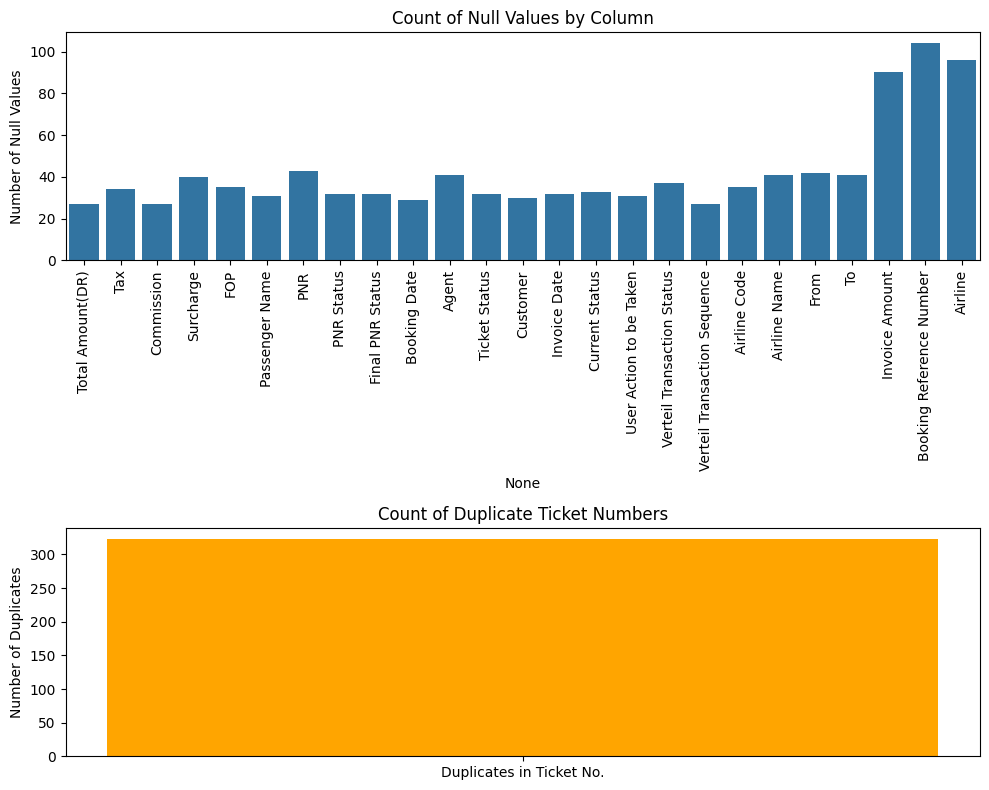

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
df = pd.read_excel('/content/Corrected_Final_Data.xlsx')

# Specify columns with null values
null_columns = ['Total Amount(DR)', 'Tax', 'Commission', 'Surcharge', 'FOP', 'Passenger Name', 'PNR',
                'PNR Status', 'Final PNR Status', 'Booking Date', 'Agent',
                'Ticket Status', 'Customer', 'Invoice Date', 'Current Status', 'User Action to be Taken',
                'Verteil Transaction Status', 'Verteil Transaction Sequence', 'Airline Code',
                'Airline Name', 'From', 'To', 'Invoice Amount', 'Booking Reference Number', 'Airline']

# Step 1: Count of null values in each column
null_counts = df[null_columns].isnull().sum()

# Step 2: Detect duplicates based on 'Ticket No.'
duplicate_ticket_no_count = df['Ticket No.'].duplicated().sum()

# Step 3: Visualizing null values and duplicates
fig, ax = plt.subplots(2, 1, figsize=(10, 8))

# Plot 1: Bar chart for null value count by column
sns.barplot(x=null_counts.index, y=null_counts.values, ax=ax[0])
ax[0].set_title('Count of Null Values by Column')
ax[0].set_ylabel('Number of Null Values')
ax[0].set_xticklabels(null_counts.index, rotation=90)

# Plot 2: Duplicates bar chart
ax[1].bar(['Duplicates in Ticket No.'], [duplicate_ticket_no_count], color='orange')
ax[1].set_title('Count of Duplicate Ticket Numbers')
ax[1].set_ylabel('Number of Duplicates')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()


In [ ]:
import pandas as pd

# Load the dataset
data = pd.read_excel('/content/shuffled_data.xlsx')  # Adjust the path as necessary

# Randomly sample 20% of the data without replacement
test_data = data.sample(frac=0.20, random_state=42)  # Use a fixed random state for reproducibility

# Save the sampled data to a new Excel file
test_data.to_excel('test_data2.xlsx', index=False)

print("Test data has been saved to 'test_data.xlsx'.")


Test data has been saved to 'test_data.xlsx'.


In [ ]:
import pandas as pd

# Load the dataset
data = pd.read_excel('rows_without_null_values (2).xlsx')  # Update the file path

# Shuffle the rows of the DataFrame
shuffled_data = data.sample(frac=1, random_state=42).reset_index(drop=True)

# Save the shuffled data to a new Excel file
shuffled_data.to_excel('shuffled_data.xlsx', index=False)

print("Shuffled data has been saved to 'shuffled_data.xlsx'.")


Shuffled data has been saved to 'shuffled_data.xlsx'.
